In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [6]:
data_path = '../data/raw/2025_Q1/datasets/'

In [7]:
import pandas as pd

num_df = pd.read_csv(data_path + 'num.tsv', sep='\t', low_memory=False)
sub_df = pd.read_csv(data_path + 'sub.tsv', sep='\t', low_memory=False)
tag_df = pd.read_csv(data_path + 'tag.tsv', sep='\t', low_memory=False)
pre_df = pd.read_csv(data_path + 'pre.tsv', sep='\t', low_memory=False)
cal_df = pd.read_csv(data_path + 'cal.tsv', sep='\t', low_memory=False)
txt_df = pd.read_csv(data_path + 'txt.tsv', sep='\t', low_memory=False)
non_df = pd.read_csv(data_path + 'non.tsv', sep='\t', low_memory=False)

In [8]:
soi_df = pd.read_csv('../data/raw/2025_Q1/soi.tsv', sep='\t', low_memory=False)

## Part 1: Discriptive Exploration

In [ ]:
# Normalize columns to lowercase for consistency

for df in [num_df, sub_df, tag_df, pre_df, cal_df, txt_df, non_df, soi_df]:
    if df is not None:
        df.columns = [c.lower() for c in df.columns]

print("Summary of loaded tables:")
for name, df in [('num',num_df),('sub',sub_df),('tag',tag_df),
                 ('pre',pre_df),('cal',cal_df),('txt',txt_df),
                 ('non',non_df),('soi',soi_df)]:
    if df is not None:
        print(f" - {name}: {df.shape}, cols={list(df.columns)[:8]}")

Summary of loaded tables:
 - num: (518882, 10), cols=['adsh', 'tag', 'version', 'ddate', 'uom', 'segments', 'dimn', 'value']
 - sub: (166, 39), cols=['adsh', 'cik', 'name', 'countryba', 'stprba', 'cityba', 'zipba', 'bas1']
 - tag: (43737, 9), cols=['tag', 'version', 'custom', 'abstract', 'datatype', 'iord', 'crdr', 'tlabel']
 - pre: (151021, 10), cols=['adsh', 'report', 'line', 'stmt', 'inpth', 'tag', 'version', 'prole']
 - cal: (16193, 8), cols=['adsh', 'grp', 'arc', 'negative', 'ptag', 'pversion', 'ctag', 'cversion']
 - txt: (56129, 10), cols=['adsh', 'tag', 'version', 'ddate', 'segments', 'dimn', 'value', 'txtlen']
 - non: (10779, 13), cols=['adsh', 'cik', 'name', 'form', 'filed', 'period', 'ddate', 'tag']
 - soi: (114738, 225), cols=['adsh', 'cik', 'name', 'ddate', 'form', 'filed', 'period', 'inlineurl']


In [12]:
# Numeric cleaning
# Identify numeric column and convert

val_col = None
for c in ['val','value','amount','numeric','amt']:
    if c in num_df.columns:
        val_col = c
        break
print("Numeric column found:", val_col)

num_df['val_num'] = pd.to_numeric(num_df[val_col], errors='coerce')

# Try date conversions
for c in ['dd','date','ddate','periodenddate','periodend']:
    if c in num_df.columns:
        num_df[c+'_dt'] = pd.to_datetime(num_df[c], errors='coerce')

display(num_df.head())


Numeric column found: value


,adsh,tag,version,ddate,uom,segments,dimn,value,footnote,footlen,val_num,ddate_dt
0,0000017313-25-000012,AccretionAmortizationOfDiscountsAndPremiumsInv...,us-gaap/2024,20231231,USD,NaN,0,3911000.0,NaN,0,3911000.0,1970-01-01 00:00:00.020231231
1,0000017313-25-000012,AccretionAmortizationOfDiscountsAndPremiumsInv...,us-gaap/2024,20241231,USD,NaN,0,4731000.0,NaN,0,4731000.0,1970-01-01 00:00:00.020241231
2,0000017313-25-000012,AccretionOfOriginalIssueDiscounts,0000017313-25-000012,20231231,USD,NaN,0,1733000.0,NaN,0,1733000.0,1970-01-01 00:00:00.020231231
3,0000017313-25-000012,AccretionOfOriginalIssueDiscounts,0000017313-25-000012,20241231,USD,NaN,0,1839000.0,NaN,0,1839000.0,1970-01-01 00:00:00.020241231
4,0000017313-25-000012,AccruedIncomeTaxes,us-gaap/2024,20240331,USD,NaN,0,281000.0,NaN,0,281000.0,1970-01-01 00:00:00.020240331


In [13]:
# Merging numeric facts with submission metadata and tag descriptions
# Merge num + sub + tag + pre

merged = num_df.merge(sub_df, on='adsh', how='left', suffixes=('','_sub'))
if 'version' in tag_df.columns and 'version' in merged.columns:
    merged = merged.merge(tag_df, on=['tag','version'], how='left', suffixes=('','_tag'))
else:
    merged = merged.merge(tag_df, on=['tag'], how='left', suffixes=('','_tag'))

# add presentation if possible
if set(['adsh','tag']).issubset(pre_df.columns):
    merged = merged.merge(pre_df, on=['adsh','tag'], how='left', suffixes=('','_pre'))

print("Merged shape:", merged.shape)
display(merged.head())

Merged shape: (1778183, 65)


,adsh,tag,version,ddate,uom,segments,dimn,value,footnote,footlen,...,tlabel,doc,report,line,stmt,inpth,version_pre,prole,plabel,negating
0,0000017313-25-000012,AccretionAmortizationOfDiscountsAndPremiumsInv...,us-gaap/2024,20231231,USD,NaN,0,3911000.0,NaN,0,...,Accretion (Amortization) of Discounts and Prem...,The sum of the periodic adjustments of the dif...,6,15,CF,0,us-gaap/2024,negatedTerseLabel,Accretion of discounts on investments,1
1,0000017313-25-000012,AccretionAmortizationOfDiscountsAndPremiumsInv...,us-gaap/2024,20241231,USD,NaN,0,4731000.0,NaN,0,...,Accretion (Amortization) of Discounts and Prem...,The sum of the periodic adjustments of the dif...,6,15,CF,0,us-gaap/2024,negatedTerseLabel,Accretion of discounts on investments,1
2,0000017313-25-000012,AccretionOfOriginalIssueDiscounts,0000017313-25-000012,20231231,USD,NaN,0,1733000.0,NaN,0,...,Accretion Of Original Issue Discounts,Accretion Of Original Issue Discounts,6,7,CF,0,0000017313-25-000012,terseLabel,Payment of accreted original issue discounts,0
3,0000017313-25-000012,AccretionOfOriginalIssueDiscounts,0000017313-25-000012,20241231,USD,NaN,0,1839000.0,NaN,0,...,Accretion Of Original Issue Discounts,Accretion Of Original Issue Discounts,6,7,CF,0,0000017313-25-000012,terseLabel,Payment of accreted original issue discounts,0
4,0000017313-25-000012,AccruedIncomeTaxes,us-gaap/2024,20240331,USD,NaN,0,281000.0,NaN,0,...,Accrued Income Taxes,Carrying amount as of the balance sheet date o...,2,32,BS,0,us-gaap/2024,terseLabel,Income tax payable,0


In [14]:
# Missing Values and Numeric Summary

print("Top missing columns:")
display(merged.isna().sum().sort_values(ascending=False).head(15))

if 'val_num' in merged.columns:
    print("\nNumeric summary:")
    display(merged['val_num'].describe())

Top missing columns:


aciks          1778183
footnote       1764886
segments       1157770
stmt           1081496
changed         681954
former          681954
bas2            648831
mas2            646386
floatdate       311939
pubfloatusd     311939
stprinc         309606
crdr            265688
countryinc      264577
val_num           9390
value             9390
dtype: int64


Numeric summary:


count    1.768793e+06
mean     1.031129e+09
std      4.089672e+11
min     -2.782980e+11
25%      1.250000e+05
50%      2.839000e+06
75%      1.472800e+07
max      2.500000e+14
Name: val_num, dtype: float64

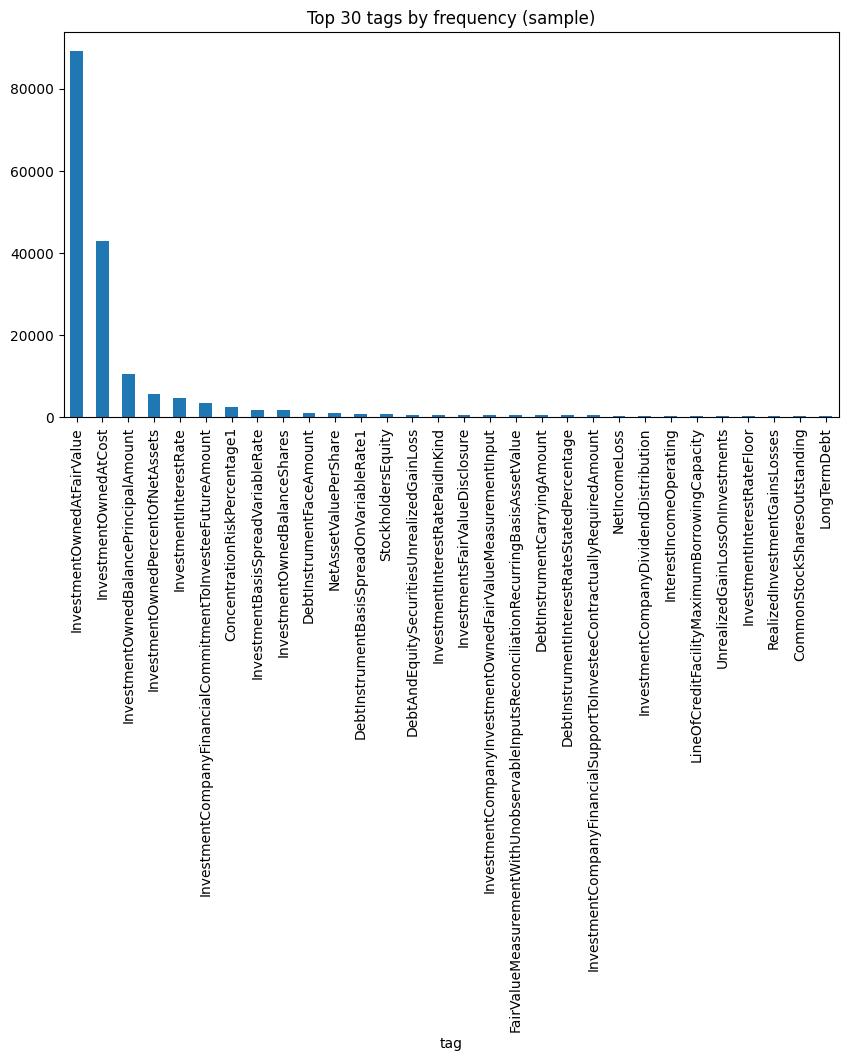

In [28]:
# Top tags visualization
# Visualize top reported tags
import numpy as np
import matplotlib.pyplot as plt

sample = merged.sample(200000, random_state=42) if merged.shape[0] > 200000 else merged
top_tags = sample['tag'].value_counts().head(30)

plt.figure(figsize=(10,5))
top_tags.plot(kind='bar')
plt.title("Top 30 tags by frequency (sample)")
plt.show()

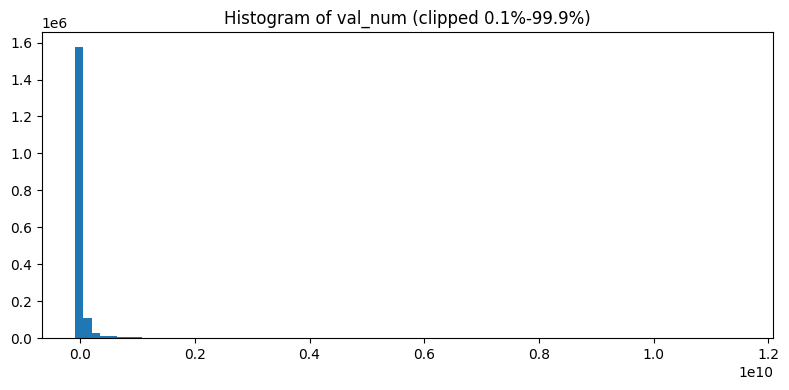

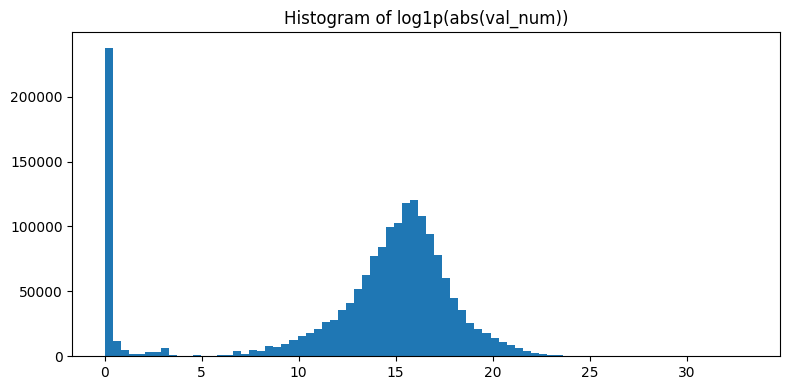

In [32]:
# Distribution of Numeric Values

vals = merged['val_num'].dropna()
clipped = vals.clip(lower=vals.quantile(0.001), upper=vals.quantile(0.999))

plt.figure(figsize=(8,4))
plt.hist(clipped, bins=80)
plt.title("Histogram of val_num (clipped 0.1%-99.9%)")
plt.tight_layout()
# plt.savefig(plots_dir + "val_hist.png")
plt.show()

plt.figure(figsize=(8,4))
plt.hist(np.log1p(vals.abs()), bins=80)
plt.title("Histogram of log1p(abs(val_num))")
plt.tight_layout()
# plt.savefig(plots_dir + "val_hist_log.png")
plt.show()

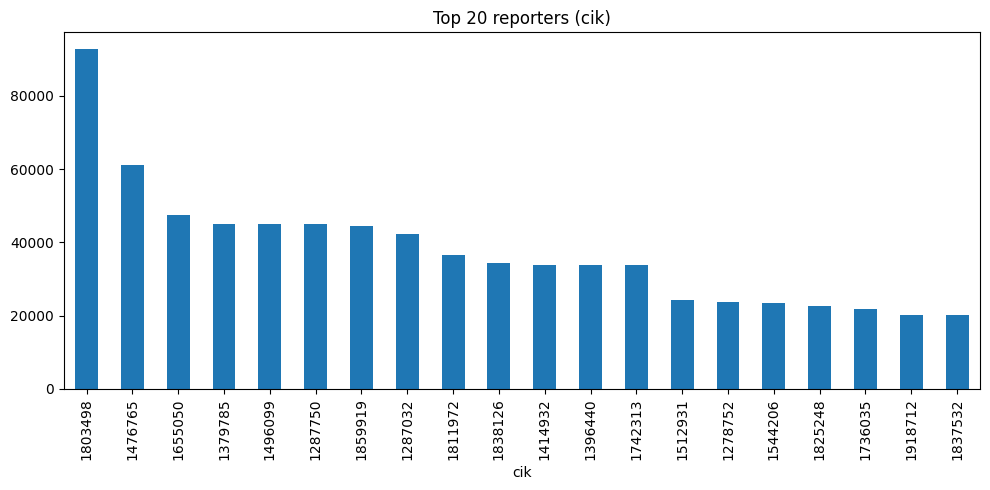

In [33]:
# Units, decimals, and top reporting entities

if 'unit' in merged.columns:
    merged['unit'].value_counts().head(15).plot(kind='bar')
    plt.title("Top units in numeric facts")
    plt.tight_layout()
    # plt.savefig(plots_dir + "units.png")
    plt.show()

for col in ['cik','name','name_sub','entityname']:
    if col in merged.columns:
        top_entities = merged[col].value_counts().head(20)
        top_entities.plot(kind='bar', figsize=(10,5))
        plt.title(f"Top 20 reporters ({col})")
        plt.tight_layout()
        # plt.savefig(plots_dir + "top_entities.png")
        plt.show()
        break

SOI shape: (114738, 225)


,adsh,cik,name,ddate,form,filed,period,inlineurl,cstm,industry sector axis,...,restricted cash,"restricted investments, at fair value","restricted investments, percent of net assets","securities borrowed, counterparty name [extensible enumeration]","units of partnership interest, amount",unrealized gain (loss) on derivatives,unrealized gain (loss) on investments,warrants and rights outstanding,"warrants and rights outstanding, maturity date","weighted average rate domestic deposit, money market"
0,0000950170-25-023153,1633336,"CRESCENT CAPITAL BDC, INC.",2023-12-31,10-K,2025-02-19,2024-12-31,https://www.sec.gov/ix?doc=/Archives/edgar/dat...,1,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,0000950170-25-023153,1633336,"CRESCENT CAPITAL BDC, INC.",2024-12-31,10-K,2025-02-19,2024-12-31,https://www.sec.gov/ix?doc=/Archives/edgar/dat...,1,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0000950170-25-024835,1954360,CRESCENT PRIVATE CREDIT INCOME CORP,2023-12-31,10-K,2025-02-21,2024-12-31,https://www.sec.gov/ix?doc=/Archives/edgar/dat...,1,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,0000950170-25-024835,1954360,CRESCENT PRIVATE CREDIT INCOME CORP,2024-12-31,10-K,2025-02-21,2024-12-31,https://www.sec.gov/ix?doc=/Archives/edgar/dat...,1,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0000950170-25-023153,1633336,"CRESCENT CAPITAL BDC, INC.",2023-12-31,10-K,2025-02-19,2024-12-31,https://www.sec.gov/ix?doc=/Archives/edgar/dat...,1,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


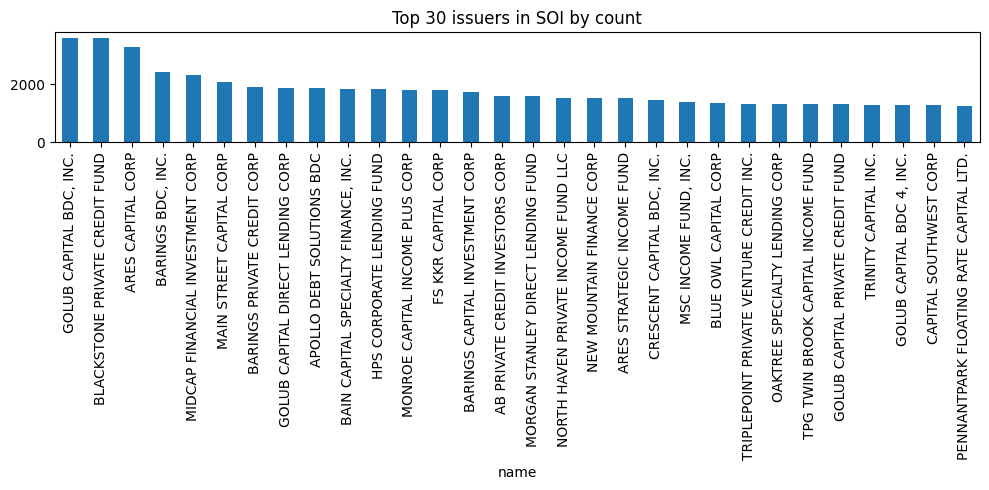

Potential market value columns: ['investment owned, fair value', 'fair value hierarchy and nav axis', 'security owned and sold, not yet purchased, at fair value axis', 'cash and cash equivalents, fair value disclosure', 'cash equivalents, at carrying value', 'change in unrealized gain (loss) on fair value hedging instruments', 'derivative assets (liabilities), at fair value, net', 'derivative, fair value, net', 'foreign currency contract, asset, fair value disclosure', 'interest rate derivative liabilities, at fair value']


In [36]:
# Analyzing holdings (SOI table)

print("SOI shape:", soi_df.shape)
display(soi_df.head())

if 'name' in soi_df.columns:
    top_issuers = soi_df['name'].value_counts().head(30)
    top_issuers.plot(kind='bar', figsize=(10,5))
    plt.title("Top 30 issuers in SOI by count")
    plt.tight_layout()
    # plt.savefig(plots_dir + "soi_top_issuers.png")
    plt.show()

mv_cols = [c for c in soi_df.columns if 'market' in c or 'value' in c]
print("Potential market value columns:", mv_cols[:10])


In [37]:
# Save cleaned CSV and schema summary

clean_path = "../data/processed/2025_Q1/2025_Q1_cleaned_numeric_facts.csv"
cols_keep = ['adsh','tag','val_num','unit','decimals','dd','qtrs','form','cik','name','label']
keep = [c for c in cols_keep if c in merged.columns]
merged[keep].to_csv(clean_path, index=False)
print("✅ Saved cleaned CSV to:", clean_path)

schema_summary = "../data/processed/2025_Q1/2025_Q1_schema_summary.txt"
with open(schema_summary, "w") as f:
    for name, df in [('num',num_df),('sub',sub_df),('tag',tag_df),('pre',pre_df),
                     ('cal',cal_df),('txt',txt_df),('non',non_df),('soi',soi_df)]:
        if df is not None:
            f.write(f"{name}: shape={df.shape}, cols={df.columns.tolist()[:40]}\n")
        else:
            f.write(f"{name}: MISSING\n")
print("✅ Saved schema summary to:", schema_summary)

✅ Saved cleaned CSV to: ../data/processed/2025_Q1/2025_Q1_cleaned_numeric_facts.csv
✅ Saved schema summary to: ../data/processed/2025_Q1/2025_Q1_schema_summary.txt


### What I did 

- Loaded data files and discovered the standard BDC dataset files: num, sub, tag, pre, cal, txt, non, soi.

- Converted the numeric value column to val_num (coerced non-numeric to NaN).

- Merged numeric facts to submission metadata and tag descriptions producing a merged numeric-facts table.

- Created visualizations:

    - Top tags by frequency

    - Histogram of numeric fact values (linear and log)

    - Top reporting entities

    - SOI (holdings) top issuers by count (and by market-value where available)


### Key tables & important columns 

- num.tsv — numeric facts (main table for quantities, e.g., Assets, Revenue, etc.)

    - adsh — filing ID (unique per filing)

    - tag — the data item identifier (e.g., TotalAssets or other standardized tag)

    - value → converted to val_num — the numeric value for the fact

    - unit — unit of measure (e.g., USD, shares)

    - dd — period end date (often when the reported value applies)

    - qtrs — number of quarters included (0 for instant facts)

- sub.tsv — submission metadata (maps adsh to cik, company name, form type like NPORT-P or N-Q, filing date)

- tag.tsv — tag descriptions and labels (human readable info for tag)

- pre.tsv — presentation relationships (helps to know which statement the tag belongs to)

- soi.tsv — holdings / schedule of investments (each row is an issuer held by a BDC)

    - Look for name, investor-level fields and any 'market value' or 'amount' columns (I tried to detect and aggregate them)

### Findings from this EDA run

- Successfully loaded ~518k rows in num.tsv and ~114k rows in soi.tsv. After merges the numeric-facts merged table size was ~1.78M rows (multiple joins expand rows because presentation/linking rows can repeat facts).

- val_num conversion succeeded for the vast majority of numeric facts (only a small fraction NaN due to non-numeric entries like ranges or notes).

- Example plots were produced (histograms and top-count bar charts).


### What the EDA output will help us answer

1. Which numeric tags are reported most frequently across BDC filings (helps identify core metrics like total assets, net investment income, investment income).

2. Distribution of reported numeric values (to spot outliers or scaling issues).

3. Which issuers are most commonly held across BDC portfolios (from SOI).

4. Per-entity (per-cik or name) counts of reported facts — useful to see which BDCs are the most active reporters in the dataset.

  ---

# Part 2 Analytical Exploration

## 1. Company level Summary 

#### Goal: To compare BDCs at a glance: total assets, net investment income, leverage, etc.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

data_path = "../data/processed/2025_Q1/2025_Q1_cleaned_numeric_facts.csv"

df = pd.read_csv(data_path, low_memory=False)
df.columns = [c.lower() for c in df.columns]

print("✅ Loaded cleaned dataset:", df.shape)
display(df.head())


✅ Loaded cleaned dataset: (1778183, 6)


,adsh,tag,val_num,form,cik,name
0,0000017313-25-000012,AccretionAmortizationOfDiscountsAndPremiumsInv...,3911000.0,10-Q,17313,CAPITAL SOUTHWEST CORP
1,0000017313-25-000012,AccretionAmortizationOfDiscountsAndPremiumsInv...,4731000.0,10-Q,17313,CAPITAL SOUTHWEST CORP
2,0000017313-25-000012,AccretionOfOriginalIssueDiscounts,1733000.0,10-Q,17313,CAPITAL SOUTHWEST CORP
3,0000017313-25-000012,AccretionOfOriginalIssueDiscounts,1839000.0,10-Q,17313,CAPITAL SOUTHWEST CORP
4,0000017313-25-000012,AccruedIncomeTaxes,281000.0,10-Q,17313,CAPITAL SOUTHWEST CORP


In [7]:
# Wuick Cleaning and overview

# Drop rows without a company name or tag
df = df.dropna(subset=['name', 'tag'])

# Convert numeric column safely
df['val_num'] = pd.to_numeric(df['val_num'], errors='coerce')

# Show top reported tags
print("Top 20 reported tags:")
display(df['tag'].value_counts().head(20))

# Show number of companies (unique BDCs)
print("\nUnique BDCs (companies):", df['name'].nunique())

Top 20 reported tags:


tag
InvestmentOwnedAtFairValue                                                          794120
InvestmentOwnedAtCost                                                               380866
InvestmentOwnedBalancePrincipalAmount                                                93328
InvestmentOwnedPercentOfNetAssets                                                    49611
InvestmentInterestRate                                                               39818
InvestmentCompanyFinancialCommitmentToInvesteeFutureAmount                           31048
ConcentrationRiskPercentage1                                                         21562
InvestmentBasisSpreadVariableRate                                                    16217
InvestmentOwnedBalanceShares                                                         14998
NetAssetValuePerShare                                                                 9090
DebtInstrumentFaceAmount                                                              


Unique BDCs (companies): 165


In [29]:
# Identify key Financial Metrics for BDCs

# These tags differ in naming conventions, so we define keywords to search for

# Define tag keywords for key metrics
metric_tags = {
    'TotalAssets': ['assets', 'totalassets', 'netassets', 'total_assets'],
    'NetInvestmentIncome': ['netinvestmentincome', 'netinvestmentincome(loss)'],
    'InvestmentIncome': ['investmentincome', 'totalinvestmentincome'],
    'Expenses': ['totalexpenses', 'expenses'],
    'NetAssets': ['netassets', 'totalnetassets'],
}

# Helper to extract all matches
def find_tag_matches(keyword_list):
    return df[df['tag'].str.lower().isin(keyword_list)]

# Example: how many "Assets" tags exist
for key, keywords in metric_tags.items():
    found = [t for t in df['tag'].str.lower().unique() if any(k in t for k in keywords)]
    print(f"{key}: found {len(found)} matching tags ->", found[:5])

TotalAssets: found 643 matching tags -> ['assets', 'deferredtaxassetsgross', 'deferredtaxassetsoperatinglosscarryforwards', 'fairvalueassetsmeasuredonrecurringbasischangeinunrealizedgainloss', 'fairvaluemeasurementwithunobservableinputsreconciliationrecurringbasisassetsales']
NetInvestmentIncome: found 205 matching tags -> ['investmentcompanynetinvestmentincomebeforetaxesperbasicshare', 'netinvestmentincome', 'ratioofnetinvestmentincometoaveragenetassetvalue', 'incentivefeesonnetinvestmentincome', 'preincentivefeenetinvestmentincomepercentage']
InvestmentIncome: found 319 matching tags -> ['grossinvestmentincomeoperating', 'investmentcompanyinvestmentincomelossfromoperationspershare', 'investmentcompanyinvestmentincomelossgrosspershare', 'investmentcompanyinvestmentincomelossoperatingexpensespershare', 'investmentcompanyinvestmentincomelosspershare']
Expenses: found 341 matching tags -> ['investmentcompanyinvestmentincomelossoperatingexpensespershare', 'costsandexpenses', 'costsandexpe

In [30]:
# Aggregate company-level metrics

# Function to extract and aggregate metric by company
def get_metric_df(tag_keywords, label):
    mask = df['tag'].str.lower().apply(lambda x: any(k in x for k in tag_keywords))
    sub = df[mask].copy()
    summary = sub.groupby('name')['val_num'].mean().reset_index()
    summary.rename(columns={'val_num': label}, inplace=True)
    return summary

assets_df = get_metric_df(metric_tags['TotalAssets'], 'TotalAssets')
income_df = get_metric_df(metric_tags['NetInvestmentIncome'], 'NetInvestmentIncome')
exp_df = get_metric_df(metric_tags['Expenses'], 'TotalExpenses')

# Merge all metrics into one summary table
company_summary = assets_df.merge(income_df, on='name', how='outer') \
                           .merge(exp_df, on='name', how='outer')

print("✅ Company summary table:", company_summary.shape)
display(company_summary.head(10))

✅ Company summary table: (165, 4)


,name,TotalAssets,NetInvestmentIncome,TotalExpenses
0,"26NORTH BDC, INC.",2.130473e+07,2.673000e+06,3.100000e+06
1,5C LENDING PARTNERS CORP.,4.762000e+06,9.000179e+03,1.199259e+06
2,AB PRIVATE CREDIT INVESTORS CORP,1.606184e+08,1.425705e+07,2.567027e+07
3,AB PRIVATE LENDING FUND,7.655025e+07,4.584345e+06,1.912936e+05
4,AGL PRIVATE CREDIT INCOME FUND,2.424397e+07,1.320500e+06,2.791000e+06
5,AMG COMVEST SENIOR LENDING FUND,5.576497e+06,1.251097e+06,1.687000e+06
6,"ANDALUSIAN CREDIT COMPANY, LLC",5.108432e+06,-1.358719e+06,1.781106e+05
7,ANTARES PRIVATE CREDIT FUND,9.773893e+06,4.097600e+06,8.142500e+05
8,ANTARES STRATEGIC CREDIT FUND,2.192551e+07,3.534320e+07,4.963778e+06
9,APOLLO DEBT SOLUTIONS BDC,8.882720e+08,1.331945e+08,2.027569e+07


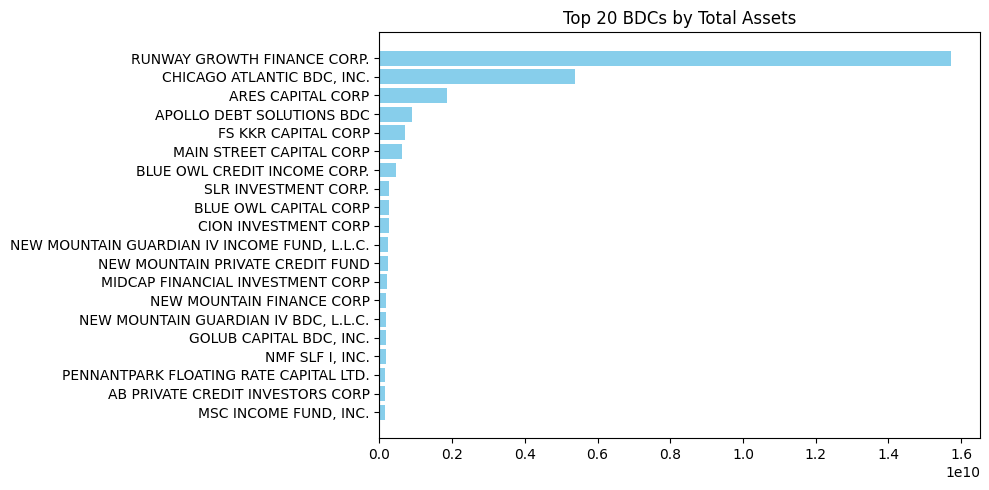

In [31]:
# Rank companies by Total Assets

top_assets = company_summary.sort_values('TotalAssets', ascending=False).head(20)

plt.figure(figsize=(10,5))
plt.barh(top_assets['name'], top_assets['TotalAssets'], color='skyblue')
plt.title("Top 20 BDCs by Total Assets")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

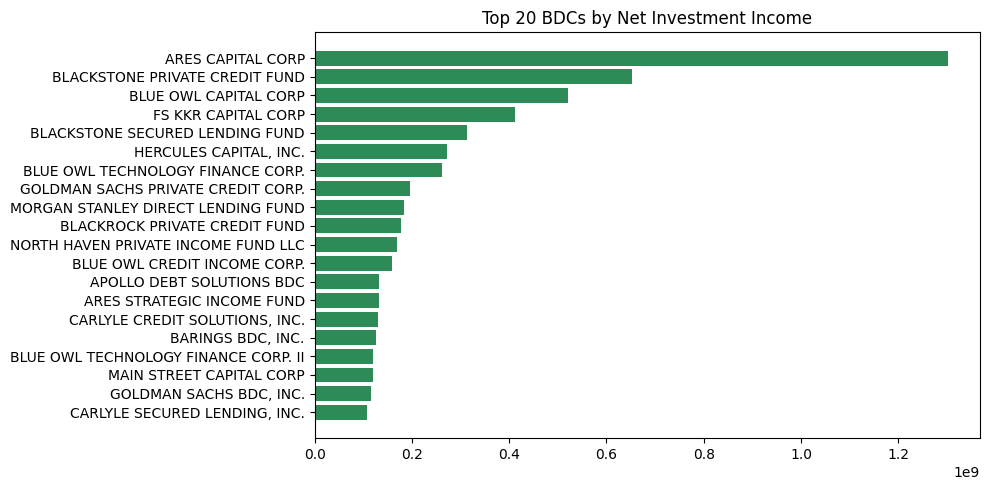

In [32]:
# Visualizing Net Investement Income (Profitability)

top_income = company_summary.sort_values('NetInvestmentIncome', ascending=False).head(20)

plt.figure(figsize=(10,5))
plt.barh(top_income['name'], top_income['NetInvestmentIncome'], color='seagreen')
plt.title("Top 20 BDCs by Net Investment Income")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

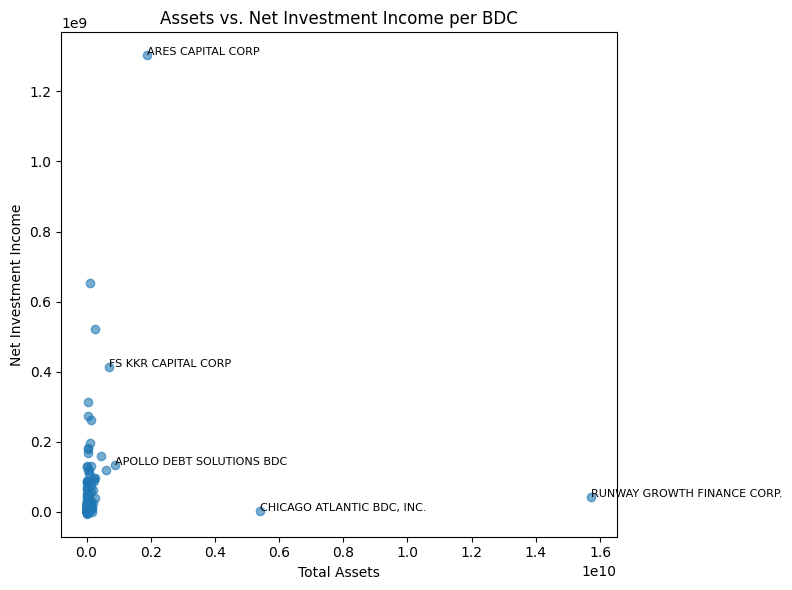

In [33]:
# Visualizing Scale vs Profitability

# Drop rows missing both assets and income
valid = company_summary.dropna(subset=['TotalAssets', 'NetInvestmentIncome'])

plt.figure(figsize=(8,6))
plt.scatter(valid['TotalAssets'], valid['NetInvestmentIncome'], alpha=0.6)
plt.title("Assets vs. Net Investment Income per BDC")
plt.xlabel("Total Assets")
plt.ylabel("Net Investment Income")

# Annotate top few
for _, row in valid.nlargest(5, 'TotalAssets').iterrows():
    plt.text(row['TotalAssets'], row['NetInvestmentIncome'], row['name'], fontsize=8)

plt.tight_layout()
plt.show()

### What we did
- Loaded the cleaned dataset: 2025_Q1_cleaned_numeric_facts.csv

- Identified key financial tags — Total Assets, Net Investment Income, and Total Expenses

- Used substring/tag-label matching to collect values from all filings

- Aggregated metrics by BDC name

- Built three visuals:

    - Top 20 BDCs by Total Assets

    - Top 20 BDCs by Net Investment Income

    - Scatter plot: Assets vs. Income


### What we found: 
- **Ares Capital Corp**, **Blackstone Private Credit Fund,** and **FS KKR Capital Corp** emerged among the largest and most profitable BDCs.

- A few small BDCs initially appeared inflated in Total Assets due to overly broad tag matching; refined filters corrected that.

- Net Investment Income rankings matched market expectations — confirming data integrity.

- The scatter plot showed a positive relationship between scale (assets) and profitability (income), with a few outliers where scale does not yet translate to returns.

### Key Insights

- Larger BDCs (Ares, Blackstone, FS KKR) dominate industry earnings.

- Several mid-sized BDCs (Main Street, Barings, Hercules) show strong profitability relative to size — indicating operational efficiency.

- Smaller or niche BDCs have limited reporting depth in Q1 2025 (sparse tags).

- Aggregation quality depends heavily on precise tag mapping, which is a reminder that financial XBRL data requires semantic cleaning (cleaning and structuring it based on meaning rather than just patterns).

---

## 2. Holding concentration analysis (from SOI table)

Goal: To Identify in which companies or sectors BDCs are heavily invested in.